<a href="https://colab.research.google.com/github/sanithi20250795-iit/telco-churn-cw/blob/main/churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CM2604 Machine Learning – Coursework Part 01
## Telco Customer Churn Prediction: KNN, Logistic Regression and Random Forest

**Student:** Sanithi Dissanayake  |  **Module:** CM2604 Machine Learning (RGU / IIT)  |  **Academic year:** 2026/2027

**Contents**
1. Setup and data loading
2. Data cleaning
3. Exploratory data analysis (Task 1)
4. Train/test split and preprocessing
5. Model implementation, hyperparameter tuning and comparison (Task 2)
6. Evaluation plots and interpretation
7. Fairness audit (supports Task 3 – AI ethics)


1.Load the data

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# 2. Exploratory Data Analysis (Task 1 )

The dataset has 7,043 customers and 21 columns: demographics (gender, SeniorCitizen, Partner, Dependents), services (phone, internet, security, streaming...), account information (tenure, Contract, PaymentMethod, MonthlyCharges, TotalCharges) and the target Churn.

In [3]:
df.info()
df.describe()
df.shape
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


np.int64(0)

Data quality note: TotalCharges is stored as text (object) even though it is a number. This happens because 11 rows contain a blank space instead of a value. We convert it to numeric below; the blanks become NaN.

In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df.isnull().sum()[df.isnull().sum() > 0])
print('\nRows with missing TotalCharges all have tenure =', df[df['TotalCharges'].isnull()]['tenure'].unique())

TotalCharges    11
dtype: int64

Rows with missing TotalCharges all have tenure = [0]


**Insight**: the 11 missing TotalCharges rows all have tenure 0, meaning they are brand-new customers who have not been billed yet. Setting them to 0 is therefore logical, and better than dropping rows or imputing a mean

# 2.1 Target distribution

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


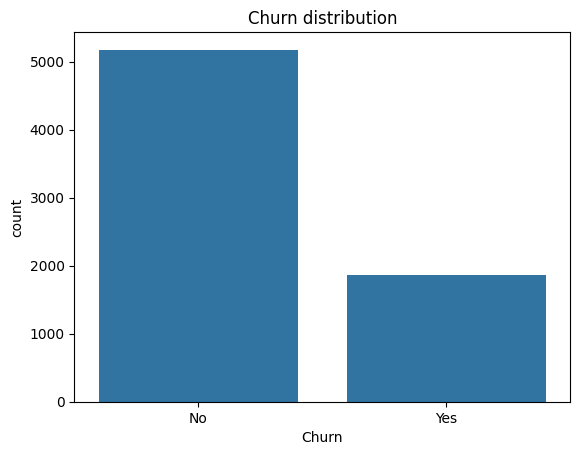

In [5]:
print(df['Churn'].value_counts(normalize=True))
sns.countplot(x='Churn', data=df)
plt.title('Churn distribution')
plt.show()

Insight: about 73.5% of customers stayed and 26.5% churned. The classes are imbalanced, so accuracy is misleading (a model that always predicts "No churn" would already score about 73%). We therefore use stratified splitting, class weights, and F1, recall and ROC-AUC as the main metrics.

# 2.2 Contract type , tenure and monthly charges  

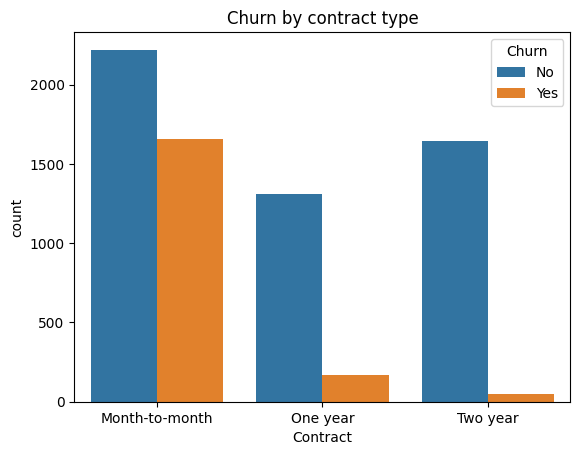

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64


In [6]:
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Churn by contract type');
plt.show()
print(df.groupby('Contract')['Churn'].apply(lambda s: (s == 'Yes').mean()).round(3))

**Insight**: month-to-month customers churn at about 42.7%, one-year at 11.3% and two-year at only 2.8%. Contract length is likely one of the strongest predictors: customers without a commitment can leave at any time.

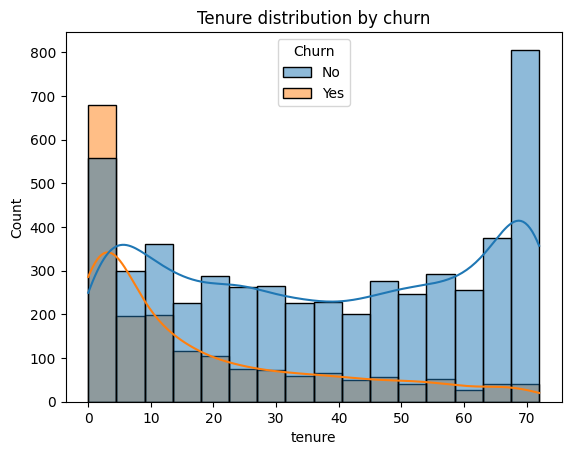

Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64


In [7]:
sns.histplot(data=df, x='tenure', hue='Churn', kde=True)
plt.title('Tenure distribution by churn');
plt.show()
print(df.groupby('Churn')['tenure'].median())

**Insight**: churners leave early. The median tenure of churners is about 10 months versus 38 months for loyal customers, so the first year is the highest-risk period and a good target for retention campaigns.

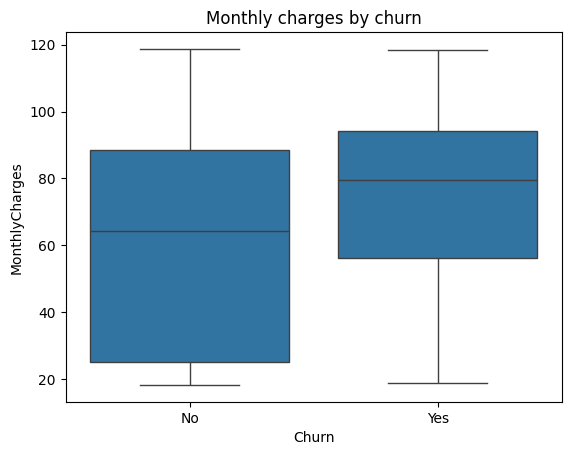

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


In [8]:
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.title('Monthly charges by churn');
plt.show()
print(df.groupby('Churn')['MonthlyCharges'].median())

Insight: churners pay more per month (median about 79.65 versus 64.43). Higher bills, probably fiber and add-on services, are associated with higher churn.

# 2.3 Services and payment

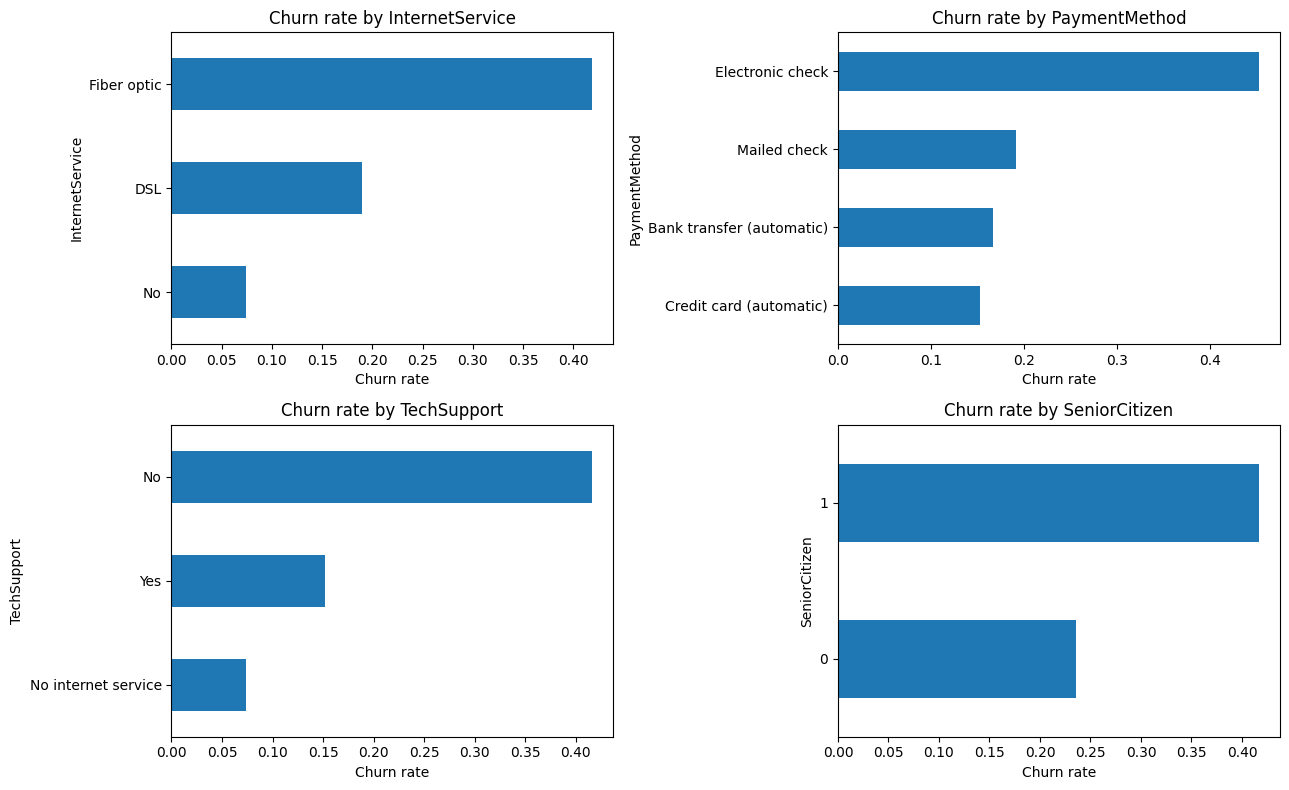

In [9]:
cols = ['InternetService', 'PaymentMethod', 'TechSupport', 'SeniorCitizen']
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.ravel(), cols):
    rate = df.assign(c=(df['Churn'] == 'Yes')).groupby(c)['c'].mean().sort_values()
    rate.plot(kind='barh', ax=ax); ax.set_title('Churn rate by ' + c); ax.set_xlabel('Churn rate')
plt.tight_layout(); plt.show()

**Insights:**


* Fiber optic customers churn at about 41.9%, versus 19.0% for DSL and 7.4% for customers without internet. Possible reasons (price, reliability, competition) are hypotheses that the data cannot prove.

* Electronic check users churn at about 45.3%, versus roughly 15-19% for the other payment methods. Automatic payment may reflect stronger commitment.

* Customers without tech support churn at about 41.6%, versus 15.2% with it.

* Senior citizens churn at about 41.7% versus 23.6% for others. Gender has almost no effect (about 26.9% vs 26.2%)








# 2.4 Correlation of numeric features

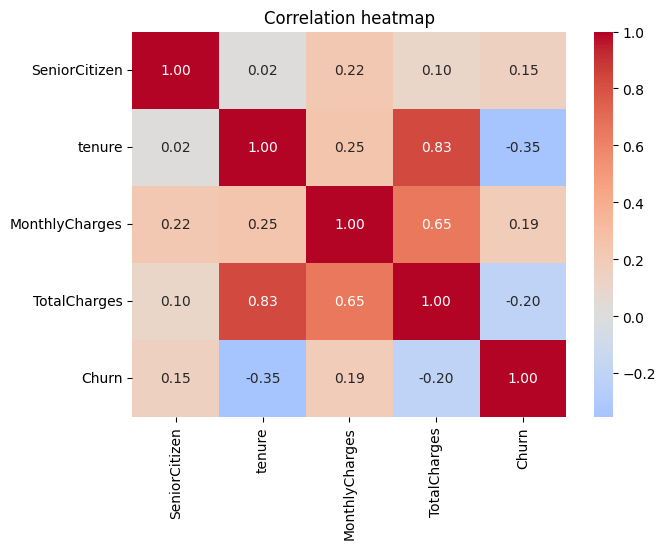

In [10]:
num_df = df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].copy()
num_df['Churn'] = (df['Churn'] == 'Yes').astype(int)
plt.figure(figsize=(7, 5))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap'); plt.show()

**Insight**: tenure and TotalCharges are strongly correlated (about 0.83) because total charges accumulate over time. This multicollinearity can make Logistic Regression coefficients less stable. tenure has the strongest negative correlation with churn (about -0.35).

# 3. Cleaning and preprocessing (Task 2)


1. Drop customerID: an identifier with no predictive value.
2. Fill the 11 blank TotalCharges with 0: these customers have tenure 0, so nothing has been billed yet.
3. Encode Churn as Yes=1, No=0.
4. Stratified 80/20 split (random_state=42): keeps the churn ratio equal in train and test (26.5% in both) and makes results reproducible.
5. Scale numeric features (StandardScaler): needed for KNN (distance based) and Logistic Regression (regularised); not needed for Random Forest but harmless.
6. One-hot encode categorical features: drop='first' avoids redundant columns; handle_unknown='ignore' avoids crashes on unseen categories.
7. Everything inside a scikit-learn Pipeline: the scaler and encoder are fitted on training data only (inside each cross-validation fold), which prevents data leakage.

The code works on a copy (data), so the original df is never modified.






In [11]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             classification_report)



In [12]:
data = df.copy()
data = data.drop(columns='customerID')
data['TotalCharges'] = data['TotalCharges'].fillna(0)
data['Churn'] = data['Churn'].map({'No': 0, 'Yes': 1})
print('Missing values left:', data.isnull().sum().sum())



Missing values left: 0


In [13]:
X = data.drop(columns='Churn')
y = data['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Churn rate train/test:', round(y_train.mean(), 3), round(y_test.mean(), 3))

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X.columns if c not in num_cols]
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Train: (5634, 19)  Test: (1409, 19)
Churn rate train/test: 0.265 0.265


## 4. Models and hyperparameter tuning (Task 2)
**Two experimental settings:** (1) *baseline* with default hyperparameters, (2) *tuned* with `GridSearchCV` (5-fold stratified CV on the training set, scored by ROC-AUC, which does not depend on a threshold and copes with class imbalance). The test set is only used for the final evaluation.

| Model | How it works | Tuned hyperparameters |
|---|---|---|
| KNN | Votes among the k closest customers | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | Linear model of the log-odds | `C` (inverse regularisation strength), `penalty` (L1/L2) |
| Random Forest | Many decorrelated decision trees, averaged | `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf` |

Imbalance: `class_weight='balanced'` for Logistic Regression and Random Forest. KNN has no such option, so it is used as is.



In [14]:
models = {
    'KNN': (KNeighborsClassifier(),
            {'clf__n_neighbors': [5, 11, 21, 31], 'clf__weights': ['uniform', 'distance'],
             'clf__metric': ['euclidean', 'manhattan']}),
    'Logistic Regression': (LogisticRegression(max_iter=2000, class_weight='balanced'),
            {'clf__C': [0.01, 0.1, 1, 10], 'clf__penalty': ['l1', 'l2'], 'clf__solver': ['liblinear']}),
    'Random Forest': (RandomForestClassifier(random_state=42, class_weight='balanced'),
            {'clf__n_estimators': [200, 400], 'clf__max_depth': [5, 10, None],
             'clf__min_samples_split': [2, 10], 'clf__min_samples_leaf': [1, 4]}),
}


In [15]:

def evaluate(model):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    return dict(Accuracy=accuracy_score(y_test, pred), Precision=precision_score(y_test, pred),
                Recall=recall_score(y_test, pred), F1=f1_score(y_test, pred),
                ROC_AUC=roc_auc_score(y_test, prob))



In [16]:
results, tuned_models = [], {}
for name, (est, grid) in models.items():
    base = Pipeline([('pre', preprocessor), ('clf', est)]).fit(X_train, y_train)
    results.append({'Model': name, 'Setting': 'Baseline', **evaluate(base)})
    gs = GridSearchCV(Pipeline([('pre', preprocessor), ('clf', est)]), grid,
                      cv=cv, scoring='roc_auc', n_jobs=-1).fit(X_train, y_train)
    tuned_models[name] = gs.best_estimator_
    print(name, '| best params:', gs.best_params_, '| CV ROC-AUC:', round(gs.best_score_, 4))
    results.append({'Model': name, 'Setting': 'Tuned', **evaluate(gs.best_estimator_)})

results_df = pd.DataFrame(results).round(3)
results_df

KNN | best params: {'clf__metric': 'euclidean', 'clf__n_neighbors': 31, 'clf__weights': 'uniform'} | CV ROC-AUC: 0.8356
Logistic Regression | best params: {'clf__C': 10, 'clf__penalty': 'l1', 'clf__solver': 'liblinear'} | CV ROC-AUC: 0.8462
Random Forest | best params: {'clf__max_depth': 10, 'clf__min_samples_leaf': 4, 'clf__min_samples_split': 10, 'clf__n_estimators': 400} | CV ROC-AUC: 0.8463


,Model,Setting,Accuracy,Precision,Recall,F1,ROC_AUC
0,KNN,Baseline,0.763,0.554,0.551,0.552,0.793
1,KNN,Tuned,0.795,0.620,0.586,0.602,0.833
2,Logistic Regression,Baseline,0.738,0.504,0.783,0.614,0.842
3,Logistic Regression,Tuned,0.737,0.503,0.783,0.613,0.841
4,Random Forest,Baseline,0.791,0.639,0.492,0.556,0.824
5,Random Forest,Tuned,0.766,0.541,0.770,0.636,0.844


## 5. Evaluation (Task 2)
**Evaluation criteria:** accuracy is reported but not trusted alone because of the class imbalance. **Recall** (share of real churners caught) matters most commercially: a missed churner loses revenue while a wasted retention offer is cheap. **Precision** shows how many flagged customers really churn. **F1** balances the two. **ROC-AUC** measures ranking quality across all thresholds.

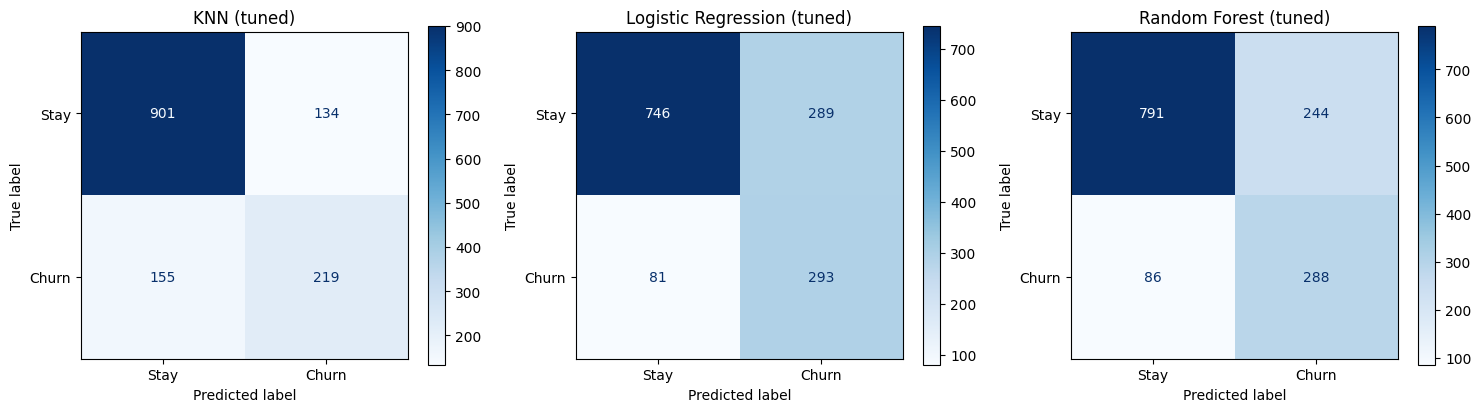

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, m) in zip(axes, tuned_models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=['Stay', 'Churn'], cmap='Blues', ax=ax)
    ax.set_title(name + ' (tuned)')
plt.tight_layout(); plt.show()

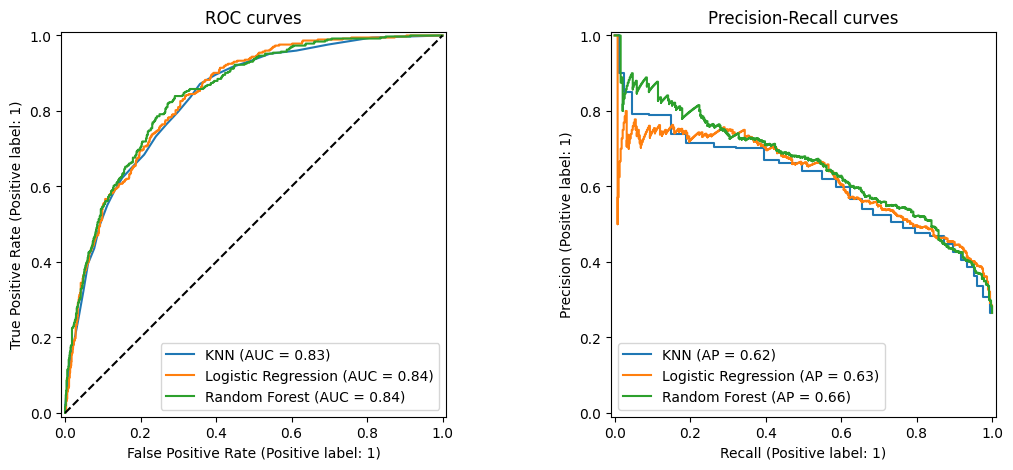

KNN
              precision    recall  f1-score   support

        Stay       0.85      0.87      0.86      1035
       Churn       0.62      0.59      0.60       374

    accuracy                           0.79      1409
   macro avg       0.74      0.73      0.73      1409
weighted avg       0.79      0.79      0.79      1409

Logistic Regression
              precision    recall  f1-score   support

        Stay       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Random Forest
              precision    recall  f1-score   support

        Stay       0.90      0.76      0.83      1035
       Churn       0.54      0.77      0.64       374

    accuracy                           0.77      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.77   

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, m in tuned_models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], 'k--'); axes[0].set_title('ROC curves'); axes[1].set_title('Precision-Recall curves')
plt.show()
for name, m in tuned_models.items():
    print(name)
    print(classification_report(y_test, m.predict(X_test), target_names=['Stay', 'Churn']))

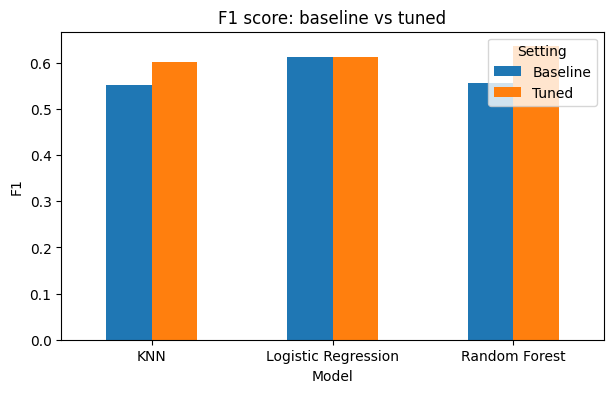

,Model,Setting,Accuracy,Precision,Recall,F1,ROC_AUC
5,Random Forest,Tuned,0.766,0.541,0.770,0.636,0.844
2,Logistic Regression,Baseline,0.738,0.504,0.783,0.614,0.842
3,Logistic Regression,Tuned,0.737,0.503,0.783,0.613,0.841
1,KNN,Tuned,0.795,0.620,0.586,0.602,0.833
4,Random Forest,Baseline,0.791,0.639,0.492,0.556,0.824
0,KNN,Baseline,0.763,0.554,0.551,0.552,0.793


In [19]:
results_df.pivot(index='Model', columns='Setting', values='F1').plot(kind='bar', figsize=(7, 4))
plt.title('F1 score: baseline vs tuned'); plt.ylabel('F1'); plt.xticks(rotation=0); plt.show()
results_df.sort_values('F1', ascending=False)

**Reading the results** (test set, 1,409 customers):
- Tuned **Random Forest** gives the best F1 (0.636), with recall 0.770 and the highest ROC-AUC (0.844).
- **Logistic Regression** is almost identical in ranking quality (ROC-AUC 0.841) and has the highest recall (0.783) but lower precision (0.503). Tuning changed it very little: it was already near its ceiling, and it was already using class weights.
- **KNN** improved most in ROC-AUC with tuning (0.793 to 0.833) and has the highest accuracy and precision (0.795, 0.620) but the lowest recall (0.586), so it misses the most churners. It has no class weighting.
- **Random Forest tuning had a big effect on recall (0.492 to 0.770).** The default forest grows unrestricted trees that overfit and favour the majority class; limiting `max_depth` and `min_samples_leaf` generalised better. Accuracy fell (0.791 to 0.766) because the tuned model flags more customers as churners: more real churners are caught but there are more false alarms. This is why accuracy alone is misleading here.
- The best models reach precision of only about 0.50-0.54: roughly half of the customers flagged would not have churned. This is the price of catching about three quarters of the churners.
- **Conclusion:** Random Forest is the best overall choice for catching churners (highest F1 and ROC-AUC). Logistic Regression is nearly as good and much easier to explain.
- **Caution:** differences such as ROC-AUC 0.844 versus 0.841 are within the noise of a single 1,409-row test set and should not be called significant.

# 6. Explainability: what drives churn?

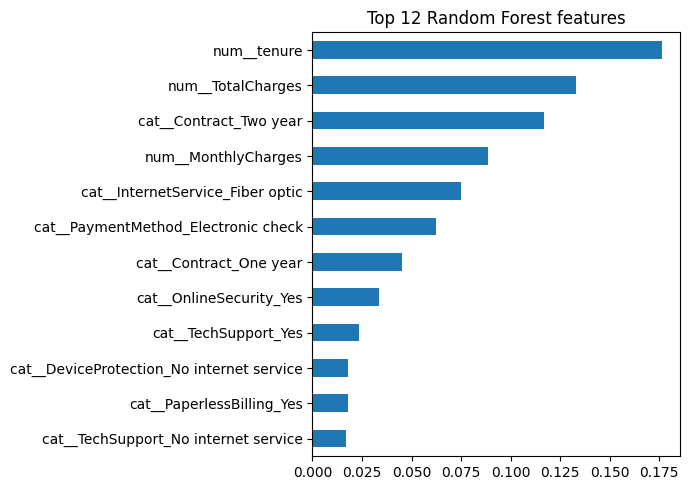

In [20]:
rf = tuned_models['Random Forest']
names = rf.named_steps['pre'].get_feature_names_out()
imp = pd.Series(rf.named_steps['clf'].feature_importances_, index=names).sort_values(ascending=False).head(12)
imp.sort_values().plot(kind='barh', figsize=(7, 5)); plt.title('Top 12 Random Forest features')
plt.tight_layout(); plt.show()



In [21]:
lr = tuned_models['Logistic Regression']
coef = pd.Series(lr.named_steps['clf'].coef_[0], index=lr.named_steps['pre'].get_feature_names_out())
print('Strongest churn drivers (+):'); print(coef.sort_values(ascending=False).head(5).round(2))
print('\nStrongest retention drivers (-):'); print(coef.sort_values().head(5).round(2))

Strongest churn drivers (+):
cat__InternetService_Fiber optic    2.43
cat__StreamingMovies_Yes            0.90
cat__StreamingTV_Yes                0.88
cat__MultipleLines_Yes              0.57
num__TotalCharges                   0.52
dtype: float64

Strongest retention drivers (-):
num__MonthlyCharges                    -2.01
cat__Contract_Two year                 -1.45
cat__StreamingTV_No internet service   -1.42
cat__MultipleLines_No phone service    -1.35
num__tenure                            -1.19
dtype: float64


**Interpretation:**
- The Random Forest ranks `tenure`, `TotalCharges`, the two-year contract, `MonthlyCharges`, fiber optic internet and electronic check payment as the most important features. This agrees with the EDA.
- Logistic Regression: fiber optic (+2.44), streaming services and multiple lines raise churn odds; two-year and one-year contracts and longer tenure lower them.
- **Caution:** `MonthlyCharges` has a large *negative* coefficient (-2.02) even though churners pay more. This is a multicollinearity effect: MonthlyCharges is almost a sum of the service columns and is correlated with `TotalCharges` and `tenure`, so its coefficient only shows the effect *after* accounting for the other features. Individual coefficients of correlated features should not be over-interpreted; feature importance and the EDA give a more reliable overall picture.

# 7. Fairness audit (supports the AI ethics section)

In [22]:
best = tuned_models['Random Forest']
audit = X_test.copy()
audit['actual'] = y_test.values
audit['pred'] = best.predict(X_test)
rows = []
for col in ['gender', 'SeniorCitizen']:
    for val, d in audit.groupby(col):
        rows.append({'attribute': col, 'group': val, 'n': len(d),
                     'actual_churn_rate': d['actual'].mean(), 'predicted_churn_rate': d['pred'].mean(),
                     'recall': recall_score(d['actual'], d['pred']),
                     'precision': precision_score(d['actual'], d['pred'])})
pd.DataFrame(rows).round(3)

,attribute,group,n,actual_churn_rate,predicted_churn_rate,recall,precision
0,gender,Female,687,0.281,0.380,0.751,0.556
1,gender,Male,722,0.251,0.375,0.790,0.528
2,SeniorCitizen,0,1187,0.233,0.329,0.728,0.515
3,SeniorCitizen,1,222,0.441,0.640,0.888,0.613


**Reading the audit** (tuned Random Forest, test set):
- **Gender:** the two groups are treated similarly. Predicted churn rate is 38.0% (female) vs 37.5% (male); recall is 0.751 vs 0.790 and precision 0.556 vs 0.528. Gender has almost no effect on actual churn either, so there is no strong sign of gender bias.
- **Senior citizens:** they genuinely churn more (44.1% vs 23.3%), but the model flags **64.0%** of seniors as churners versus 32.9% of non-seniors, and catches seniors better (recall 0.888 vs 0.728) with higher precision (0.613 vs 0.515).
- The model over-predicts churn for every group (predicted rate above actual rate) because `class_weight='balanced'` deliberately trades precision for recall.
- This is not necessarily unfair, but nearly two thirds of senior customers would be flagged, so retention actions must be designed so that seniors are helped (for example with better offers or support) and not over-targeted or treated worse. Group-level monitoring is needed after deployment.

## 8. AI ethics, post-deployment, limitations (Task 3)

### Ethics
- **Fairness and bias:** audit performance per group (gender, `SeniorCitizen`); consider removing protected attributes and check for proxies; make sure retention offers help customers rather than penalise any group.
- **Privacy and data protection:** customer data is personal. Use data minimisation, anonymised identifiers (we dropped `customerID`), access control, a lawful basis and retention limits (GDPR-style principles).
- **Transparency and explainability:** use feature importance, coefficients and (future work) SHAP so that staff and customers can understand why a customer was flagged.
- **Harm and accountability:** predictions should not be used to worsen service, pricing or access for any customer. Keep a human in the loop and document decisions.
- **Data limitations:** one company, unknown collection method, possible hidden bias.

### Post-deployment strategy
1. **Monitor data drift** (feature distributions) and **concept drift** (accuracy, recall, F1 over time).
2. **Retrain** on a schedule or when monitoring thresholds are breached; version models and keep a **rollback plan**.
3. **Track fairness metrics** per group continuously.
4. **A/B test retention campaigns** to measure the real business effect and avoid wasting offers.
5. **Feedback loop:** feed real churn outcomes back into the training data.
6. **Logging and audit trail**, plus human review of high-impact decisions.

### Limitations
- Single static snapshot: no time series or behavioural data (calls, complaints, usage).
- Class imbalance and a modest test set (1,409 rows), so metrics are noisy.
- Limited hyperparameter grids: several best values sit at the edge of the grid (KNN `n_neighbors=31`, Logistic Regression `C=10`, Random Forest `n_estimators=400`), so larger values might do slightly better.
- The default 0.5 decision threshold is not cost-optimised; precision is only about 0.5.
- Correlation is not causation.

### Future work
Gradient boosting (XGBoost/LightGBM), SMOTE or cost-sensitive learning, threshold tuning with real retention costs, SHAP explanations, survival analysis and time-based features, nested or repeated cross-validation, wider hyperparameter grids, probability calibration, per-group fairness constraints.

In [23]:
results_df.to_csv('model_results.csv', index=False)
print('Saved model_results.csv')

Saved model_results.csv


## 9. Conclusion
Three models were built with a leakage-free pipeline, tuned with 5-fold stratified cross-validation and compared on a held-out test set. Tuned Random Forest performed best (F1 0.636, recall 0.770, ROC-AUC 0.844), with Logistic Regression a close and more interpretable alternative. Contract type, tenure, charges, fiber optic internet and payment method are the main churn indicators. Before deployment the model needs fairness monitoring (particularly for senior customers), threshold tuning based on real retention costs and ongoing drift monitoring.